# 📚 Books Data Analysis & Exploratory Data Analysis (EDA)

**Author:** Ranjith B  
**Degree:** B.Tech Computer Science & Business Systems (CSBS)  
**Institution:** Nehru Institute of Engineering and Technology, Coimbatore  
**Data Origin:** [Books to Scrape](https://books.toscrape.com/) (1,000 titles across all 50 catalog pages)  
**Companion Scraper:** [`books-web-scraping`](https://github.com/ranjithbrs/books-web-scraping)  

---

## 🎯 Project Overview & Objectives
This project presents an end-to-end analytical study of 1,000 books extracted from an online book catalog. Objectives include:
1. **Data Hygiene & Verification**: Audit missing values, verify record completeness, and analyze duplicate entries.
2. **Data Normalization & Cleaning**: Fix currency strings into numerical floats, map text ratings to ordinal numbers, and resolve text character encoding artifacts.
3. **Feature Engineering**: Derive title metrics (length, word count) and segment catalog inventory into consumer retail price tiers.
4. **Hypothesis Testing**: Formally evaluate the relationship between retail price and customer satisfaction ratings ($r = 0.028$).
5. **Strategic Business Insights**: Derive commercial recommendations for inventory, pricing, and merchandising.


## 1. Environment Setup & Data Loading

We import standard scientific Python libraries: **Pandas** for data wrangling, **NumPy** for numerical operations, and **Matplotlib** / **Seaborn** for visualizations.


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set global visualization theme
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams.update({
    'figure.figsize': (10, 5.5),
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'figure.titlesize': 16
})

# Resolve file path (supports running from root or notebooks/ folder)
data_path = os.path.join('..', 'data', 'raw', 'books_all_pages.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'raw', 'books_all_pages.csv')
if not os.path.exists(data_path):
    data_path = 'books_all_pages.csv'

df_raw = pd.read_csv(data_path)
print(f'[INFO] Raw dataset loaded successfully!')
print(f'       Total Records : {df_raw.shape[0]:,}')
print(f'       Total Features: {df_raw.shape[1]}')
print(f'       Columns       : {df_raw.columns.tolist()}')
print('\nFirst 5 Records:')
print(df_raw.head().to_string())


[INFO] Raw dataset loaded successfully!
       Total Records : 1,000
       Total Features: 4
       Columns       : ['Title', 'Price', 'Rating', 'Availability']

First 5 Records:
                                   Title   Price Rating Availability
0                   A Light in the Attic  £51.77  Three     In stock
1                     Tipping the Velvet  £53.74    One     In stock
2                             Soumission  £50.10    One     In stock
3                          Sharp Objects  £47.82   Four     In stock
4  Sapiens: A Brief History of Humankind  £54.23   Five     In stock


## 2. Data Quality, Missing Values & Duplicate Audit

Before applying transformations, we perform a formal data health check:
- **Completeness Check**: Scan for null or missing values across all features.
- **Exact Row Duplicates**: Check for identical repeated records.
- **Title-Level Duplicate Audit**: Detect if duplicate titles exist and inspect their listings.


In [5]:
print('=== 1. MISSING VALUES AUDIT ===')
null_report = df_raw.isnull().sum()
print(null_report.to_string())
print(f'Total Missing Cells: {null_report.sum()} (100% Complete)')

print('\n=== 2. EXACT ROW DUPLICATES ===')
exact_dups = df_raw.duplicated().sum()
print(f'Exact Duplicate Rows: {exact_dups}')

print('\n=== 3. TITLE-LEVEL DUPLICATE AUDIT ===')
title_dups_count = df_raw['Title'].duplicated().sum()
print(f'Duplicate Titles Count: {title_dups_count}')

if title_dups_count > 0:
    dup_rows = df_raw[df_raw['Title'].duplicated(keep=False)]
    print('\nInspecting Duplicate Title Records:')
    print(dup_rows.to_string())


=== 1. MISSING VALUES AUDIT ===
Title           0
Price           0
Rating          0
Availability    0
Total Missing Cells: 0 (100% Complete)

=== 2. EXACT ROW DUPLICATES ===
Exact Duplicate Rows: 0

=== 3. TITLE-LEVEL DUPLICATE AUDIT ===
Duplicate Titles Count: 1

Inspecting Duplicate Title Records:
                      Title   Price Rating Availability
236  The Star-Touched Queen  £46.02   Five     In stock
358  The Star-Touched Queen  £32.30   Five     In stock


### 🔍 Duplicate Audit Finding
- **Exact Row Duplicates:** Exactly **0** rows are duplicated.
- **Duplicate Title:** Exactly **1** title (*"The Star-Touched Queen"*) appears twice:
  1. Record #236: Price = **£46.02**, Rating = **Five**, In stock
  2. Record #358: Price = **£32.30**, Rating = **Five**, In stock
- **Domain Decision:** Both records are retained. They represent two distinct catalog listings with different prices on the source platform, without asserting why.


## 3. Data Cleaning & Normalization Pipeline

We execute three core cleaning steps:
1. **Title Encoding Repair**: Fix Windows-1252/Latin-1 misinterpretations of UTF-8 multi-byte characters (e.g. `â€™` to `’`).
2. **Numeric Price Extraction**: Strip currency symbols (`£`) and cast to `float64`.
3. **Ordinal Rating Mapping**: Convert string ratings (`'One'` .. `'Five'`) into integers (`1` .. `5`).
4. **Availability Normalization**: Clean whitespace and verify stock status.


In [8]:
df_clean = df_raw.copy()

# 1. Clean and repair title encoding
def repair_text(text):
    if not isinstance(text, str):
        return text
    try:
        return text.encode('latin1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text.strip()

df_clean['title'] = df_clean['Title'].apply(repair_text).str.strip()

# 2. Extract numeric price in GBP
df_clean['price_gbp'] = df_clean['Price'].astype(str).str.extract(r'(\d+\.\d+)')[0].astype(float)

# 3. Map textual rating to integer 1-5
rating_map = {'One': 1, 'Two': 2, 'Three': 3, 'Four': 4, 'Five': 5}
df_clean['rating_numeric'] = df_clean['Rating'].map(rating_map).astype(int)

# 4. Normalize Availability
df_clean['in_stock'] = df_clean['Availability'].str.contains('In stock', case=False, na=False)

print('[INFO] Cleaning transformations complete!')
print(df_clean[['title', 'price_gbp', 'rating_numeric', 'in_stock']].head().to_string())


[INFO] Cleaning transformations complete!
                                   title  price_gbp  rating_numeric  in_stock
0                   A Light in the Attic      51.77               3      True
1                     Tipping the Velvet      53.74               1      True
2                             Soumission      50.10               1      True
3                          Sharp Objects      47.82               4      True
4  Sapiens: A Brief History of Humankind      54.23               5      True


## 4. Feature Engineering: Price Tiers & Text Metrics

To enable deeper business intelligence, we engineer three analytical features:
- `title_length`: Total character count of the cleaned title.
- `title_word_count`: Number of words in the title.
- `price_tier`: Categorized into consumer retail tiers (Mutually Exclusive & Collectively Exhaustive):
  - **Budget (< £20)**: `[£0.00, £20.00)`
  - **Mid-Range (£20 - £40)**: `[£20.00, £40.00)`
  - **Premium (> £40)**: `[£40.00, ∞)`


In [10]:
df_clean['title_length'] = df_clean['title'].str.len()
df_clean['title_word_count'] = df_clean['title'].apply(lambda s: len(s.split()))

price_bins = [0, 20.0, 40.0, float('inf')]
price_labels = ['Budget (< £20)', 'Mid-Range (£20 - £40)', 'Premium (> £40)']
df_clean['price_tier'] = pd.cut(df_clean['price_gbp'], bins=price_bins, labels=price_labels, right=False)

print('=== ENGINEERED FEATURES PREVIEW ===')
print(df_clean[['title', 'title_length', 'title_word_count', 'price_tier']].head().to_string())

print('\n=== PRICE TIER DISTRIBUTION ===')
print(df_clean['price_tier'].value_counts().to_string())


=== ENGINEERED FEATURES PREVIEW ===
                                   title  title_length  title_word_count       price_tier
0                   A Light in the Attic            20                 5  Premium (> £40)
1                     Tipping the Velvet            18                 3  Premium (> £40)
2                             Soumission            10                 1  Premium (> £40)
3                          Sharp Objects            13                 2  Premium (> £40)
4  Sapiens: A Brief History of Humankind            37                 6  Premium (> £40)

=== PRICE TIER DISTRIBUTION ===
price_tier
Premium (> £40)          403
Mid-Range (£20 - £40)    401
Budget (< £20)           196


## 5. Statistical Summary of Cleaned Data

Summary statistics for all quantitative features across the 1,000-book catalog:


In [12]:
stats_df = df_clean[['price_gbp', 'rating_numeric', 'title_length', 'title_word_count']].describe().round(2)
print(stats_df.to_string())


       price_gbp  rating_numeric  title_length  title_word_count
count    1000.00         1000.00       1000.00           1000.00
mean       35.07            2.92         39.10              6.74
std        14.45            1.43         25.75              4.20
min        10.00            1.00          2.00              1.00
25%        22.11            2.00         19.00              3.00
50%        35.98            3.00         35.00              6.00
75%        47.46            4.00         53.00              9.00
max        59.99            5.00        204.00             27.00


## 6. Exploratory Visualizations & Empirical Findings

### 6.1 Univariate Analysis: Catalog Price Distribution
Let us evaluate the shape, spread, and central tendency of book prices.


Price Mean  : £35.07
Price Median: £35.98
Price Range : £10.00 to £59.99


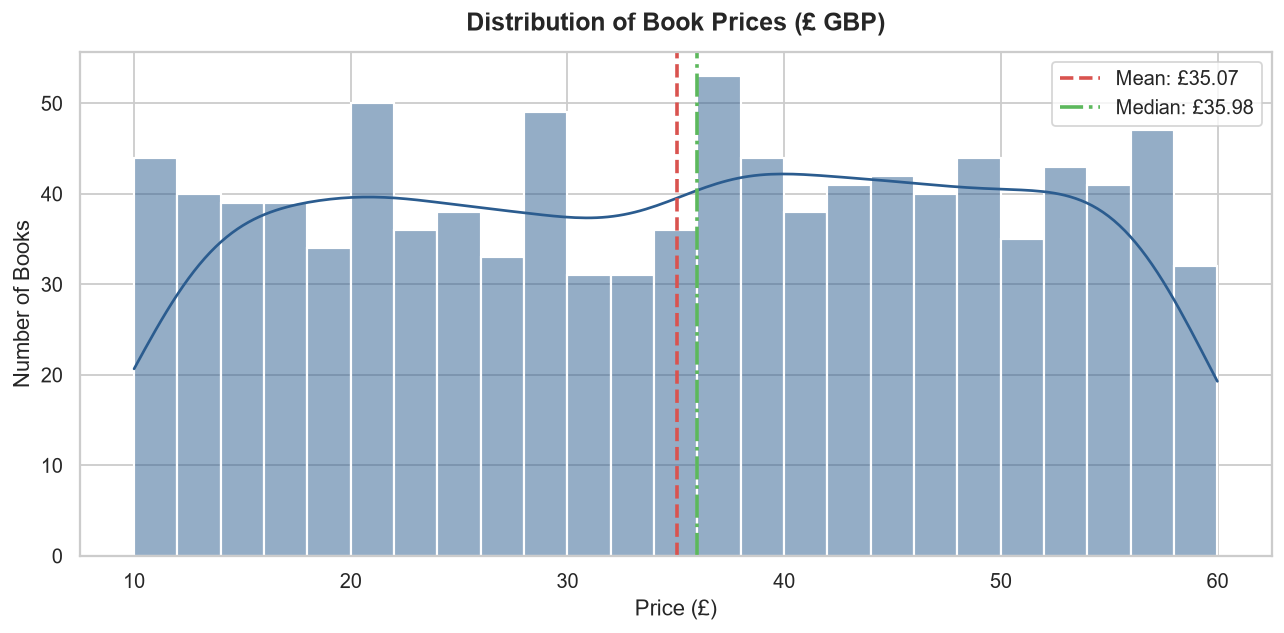

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
mean_price = df_clean['price_gbp'].mean()
median_price = df_clean['price_gbp'].median()

sns.histplot(df_clean['price_gbp'], kde=True, bins=25, color='#2b5c8f', edgecolor='white', linewidth=1.2, ax=ax)
ax.axvline(mean_price, color='#d9534f', linestyle='--', linewidth=2, label=f'Mean: £{mean_price:.2f}')
ax.axvline(median_price, color='#5cb85c', linestyle='-.', linewidth=2, label=f'Median: £{median_price:.2f}')

ax.set_title('Distribution of Book Prices (£ GBP)', pad=12, weight='bold')
ax.set_xlabel('Price (£)')
ax.set_ylabel('Number of Books')
ax.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()

print(f'Price Mean  : £{mean_price:.2f}')
print(f'Price Median: £{median_price:.2f}')
print(f'Price Range : £{df_clean["price_gbp"].min():.2f} to £{df_clean["price_gbp"].max():.2f}')


### 6.2 Univariate Analysis: Star Ratings Breakdown
Are book ratings normally distributed, skewed positively, or uniform across the catalog?


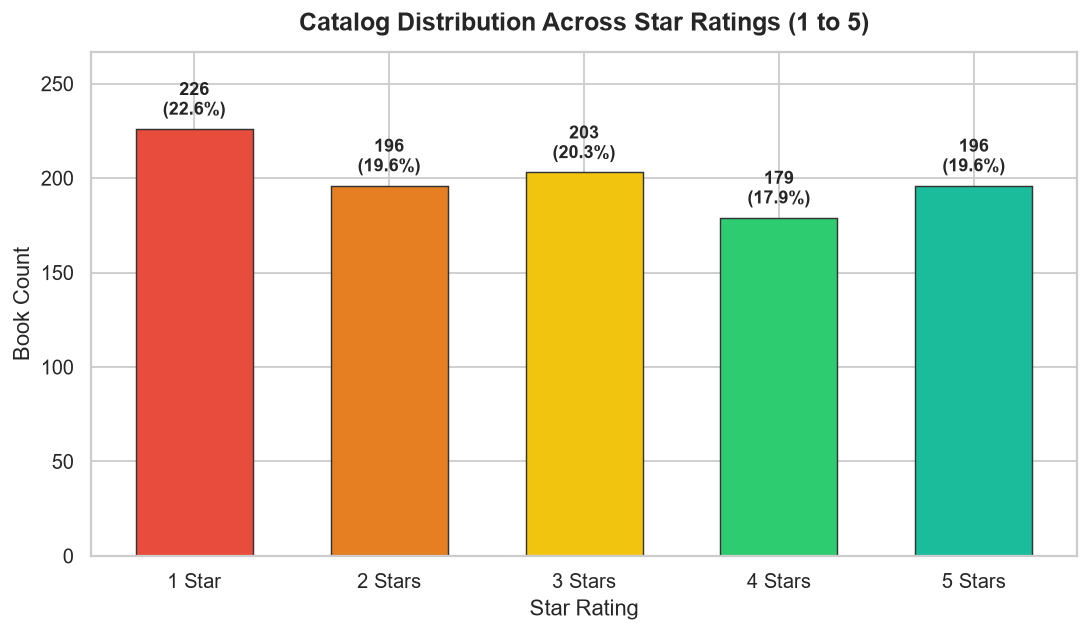

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 5))
rating_counts = df_clean['rating_numeric'].value_counts().sort_index()
palette = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#1abc9c']

bars = ax.bar(rating_counts.index, rating_counts.values, color=palette, edgecolor='#333333', linewidth=0.8, width=0.6)
for bar in bars:
    h = bar.get_height()
    pct = (h / len(df_clean)) * 100
    ax.annotate(f'{h}\n({pct:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontsize=10, weight='bold')

ax.set_title('Catalog Distribution Across Star Ratings (1 to 5)', pad=12, weight='bold')
ax.set_xlabel('Star Rating')
ax.set_ylabel('Book Count')
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars'])
ax.set_ylim(0, max(rating_counts.values) * 1.18)
plt.tight_layout()
plt.show()


### 6.3 Bivariate Hypothesis Testing: Does Price Vary by Star Rating?
We test whether higher customer satisfaction ratings translate to higher retail book prices.


In [18]:
rating_stats = df_clean.groupby('rating_numeric')['price_gbp'].agg(
    Count='count',
    Mean_Price='mean',
    Median_Price='median',
    Std_Dev='std',
    Min_Price='min',
    Max_Price='max'
).round(2)
print('=== PRICE SUMMARY BY RATING TIER ===')
print(rating_stats.to_string())

corr_val = df_clean['price_gbp'].corr(df_clean['rating_numeric'])
print(f'\nPearson Correlation (Price vs. Rating): r = {corr_val:.4f} (Very Weak Linear Association)')


=== PRICE SUMMARY BY RATING TIER ===
                Count  Mean_Price  Median_Price  Std_Dev  Min_Price  Max_Price
rating_numeric                                                                
1                 226       34.56         34.77    13.95      10.40      59.64
2                 196       34.81         36.22    13.61      10.02      59.95
3                 203       34.69         33.78    14.70      10.16      59.99
4                 179       36.09         37.80    15.08      10.01      59.45
5                 196       35.37         36.90    15.05      10.00      59.92

Pearson Correlation (Price vs. Rating): r = 0.0282 (Very Weak Linear Association)


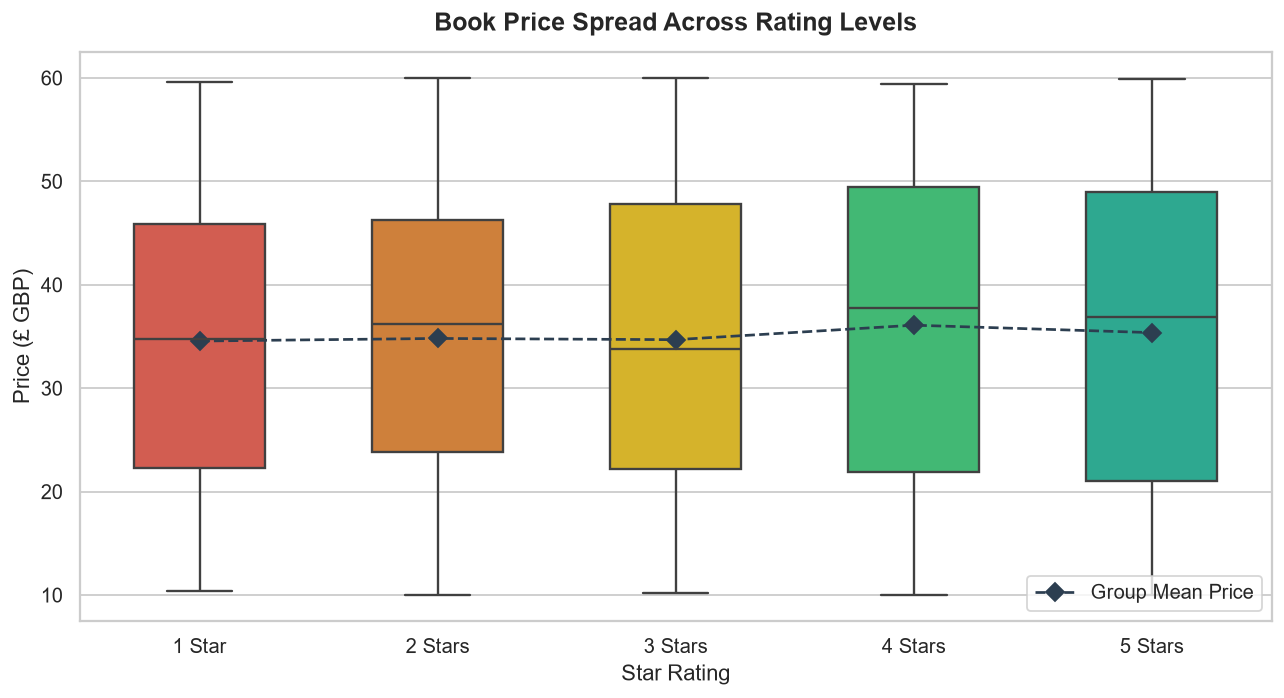

In [19]:
fig, ax = plt.subplots(figsize=(10, 5.5))
palette = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#1abc9c']
sns.boxplot(x='rating_numeric', y='price_gbp', hue='rating_numeric', data=df_clean,
            palette=palette, ax=ax, fliersize=4, linewidth=1.3, width=0.55, legend=False)

# Overlay group mean points
means = df_clean.groupby('rating_numeric')['price_gbp'].mean()
ax.plot(range(len(means)), means.values, color='#2c3e50', marker='D', markersize=7,
        linestyle='--', linewidth=1.5, label='Group Mean Price')

ax.set_title('Book Price Spread Across Rating Levels', pad=12, weight='bold')
ax.set_xlabel('Star Rating')
ax.set_ylabel('Price (£ GBP)')
ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars'])
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


### 6.4 Market Segmentation: Price Tiers Breakdown
A donut chart showing the inventory distribution across retail price brackets.


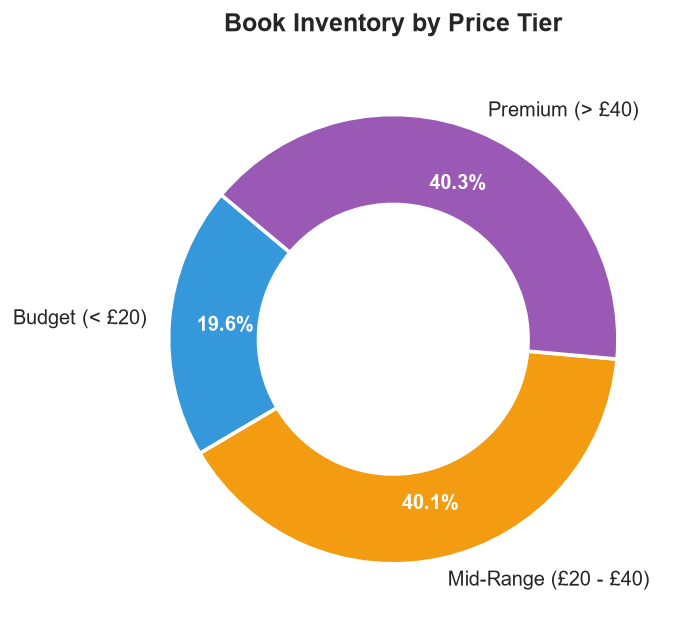

In [21]:
tier_counts = df_clean['price_tier'].value_counts()[['Budget (< £20)', 'Mid-Range (£20 - £40)', 'Premium (> £40)']]
fig, ax = plt.subplots(figsize=(7, 5))
colors = ['#3498db', '#f39c12', '#9b59b6']

wedges, texts, autotexts = ax.pie(
    tier_counts.values, labels=tier_counts.index, autopct='%1.1f%%',
    startangle=140, colors=colors, wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2), pctdistance=0.75
)
for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_weight('bold')
    autotext.set_color('white')

ax.set_title('Book Inventory by Price Tier', pad=15, weight='bold')
plt.tight_layout()
plt.show()


### 6.5 Catalog Price Extremes: Most Expensive vs. Most Affordable


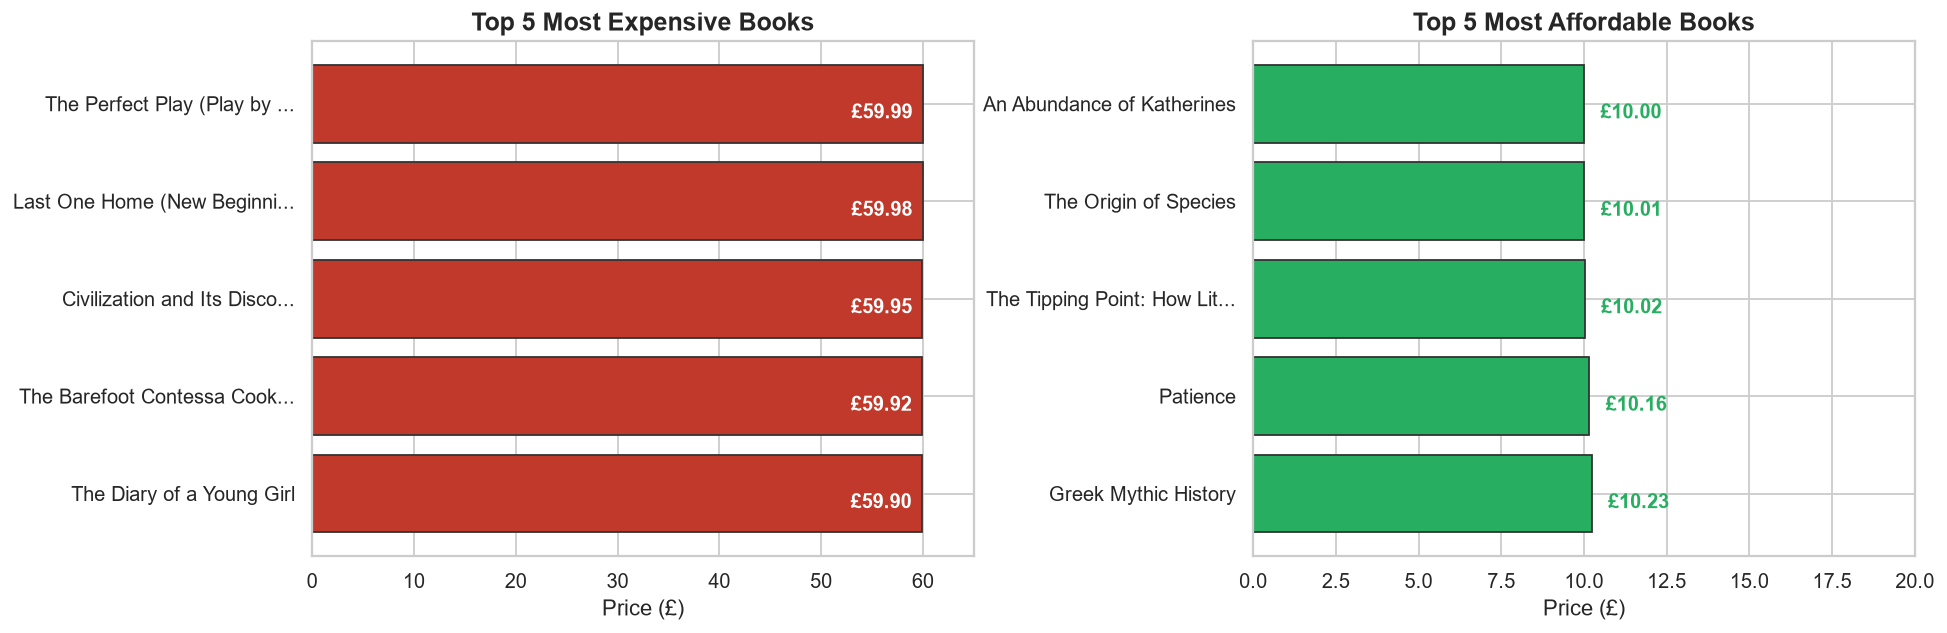

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Top 5 most expensive
top_expensive = df_clean.sort_values(by='price_gbp', ascending=False).head(5).copy()
top_expensive['short_title'] = top_expensive['title'].apply(lambda t: t[:26] + '...' if len(t) > 26 else t)

# Top 5 cheapest
top_cheapest = df_clean.sort_values(by='price_gbp', ascending=True).head(5).copy()
top_cheapest['short_title'] = top_cheapest['title'].apply(lambda t: t[:26] + '...' if len(t) > 26 else t)

bars1 = ax1.barh(top_expensive['short_title'][::-1], top_expensive['price_gbp'][::-1], color='#c0392b', edgecolor='#333333')
for bar in bars1:
    w = bar.get_width()
    ax1.text(w - 7, bar.get_y() + 0.25, f'£{w:.2f}', color='white', weight='bold')
ax1.set_title('Top 5 Most Expensive Books', weight='bold')
ax1.set_xlabel('Price (£)')
ax1.set_xlim(0, 65)

bars2 = ax2.barh(top_cheapest['short_title'][::-1], top_cheapest['price_gbp'][::-1], color='#27ae60', edgecolor='#333333')
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.5, bar.get_y() + 0.25, f'£{w:.2f}', color='#27ae60', weight='bold')
ax2.set_title('Top 5 Most Affordable Books', weight='bold')
ax2.set_xlabel('Price (£)')
ax2.set_xlim(0, 20)

plt.tight_layout()
plt.show()


## 7. Business-Oriented Findings & Strategic Takeaways

1. **Very Weak Linear Association Between Price and Rating ($r = 0.028$)**:
   - The observed linear association between price and rating is very weak ($r = 0.028$). The average price for a 5-star title (£35.37) is virtually identical to that of a 1-star title (£34.56).
   - **Strategic Action:** Algorithmic search and recommendation engines should never use retail price as a proxy for satisfaction or quality.

2. **Mid-to-High Market Positioning (80.4%)**:
   - 804 out of 1,000 books cost £20 or more. Only 19.6% fall into the Budget (< £20) category.
   - **Strategic Action:** Merchandisers can drive top-of-funnel customer acquisition by sourcing and promoting more entry-level titles in the £5–£15 bracket.

3. **Gateway Merchandising (High Ratings at Low Cost)**:
   - Titles like *An Abundance of Katherines* (£10.00, 5★) and *Greek Mythic History* (£10.23, 5★) provide maximum customer value at minimal cost.
   - **Strategic Action:** Feature these top-rated affordable books in welcome emails, introductory bundles, and cart-addition suggestions.

4. **Dynamic Value-Based Markdown Potential**:
   - Low-rated titles priced above £55 (e.g. *Civilization and Its Discontents*, £59.95, 2★) risk slow inventory turnover.
   - **Strategic Action:** Apply targeted 15–20% discounts to underperforming 1-star and 2-star premium books to liquidate inventory.
